# Evaluator-Optimizer Loop

This notebook demonstrates and evaluates the Assessor's **evaluator-optimizer loop**.

1. A **grader** LLM scores a learner's Python submission (after the code is executed with the REPL tool).
2. A **critic** LLM reviews the grade for consistency with the real execution output and for specific, actionable feedback.
3. If the critic rejects the grade, the grader runs again with the critique. The loop stops after **3 iterations at most**.

In [1]:
import sys
import time
from pathlib import Path

# Make the project root importable (this notebook lives in notebooks/)
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from src.agents.assessor_agent import MAX_ITERATIONS, build_assessor_graph

assessor = build_assessor_graph()
print("Max iterations:", MAX_ITERATIONS)

Max iterations: 3


## Test submissions

Three submissions for the same assignment, designed to exercise different behaviours:

| Case | Description | Expected behaviour |
|---|---|---|
| correct | Correct and documented | High score |
| wrong_output | Runs, but returns the wrong value (`+ 1` bug) | Low correctness, specific feedback |
| crash | Raises an error | Error message used in the feedback |

In [2]:
ASSIGNMENT = (
    "Write a function average(numbers) that returns the mean of a list, "
    "then print average([3, 7, 10, 15]). Expected output: 8.75"
)

SUBMISSIONS = {
    "correct": (
        "def average(numbers):\n"
        "    \"\"\"Return the mean of a list of numbers.\"\"\"\n"
        "    return sum(numbers) / len(numbers)\n"
        "\n"
        "print(average([3, 7, 10, 15]))"
    ),
    "wrong_output": (
        "def average(numbers):\n"
        "    return sum(numbers) / len(numbers) + 1\n"
        "print(average([3, 7, 10, 15]))"
    ),
    "crash": (
        "def average(numbers):\n"
        "    return sum(numbers) / len(numbers)\n"
        "print(average([]))"
    ),
}

for name, code_text in SUBMISSIONS.items():
    print(f"--- {name} ---\n{code_text}\n")

--- correct ---
def average(numbers):
    """Return the mean of a list of numbers."""
    return sum(numbers) / len(numbers)

print(average([3, 7, 10, 15]))

--- wrong_output ---
def average(numbers):
    return sum(numbers) / len(numbers) + 1
print(average([3, 7, 10, 15]))

--- crash ---
def average(numbers):
    return sum(numbers) / len(numbers)
print(average([]))



## Run the loop

Each submission takes up to 7 model calls, so a pause is added between cases to stay inside the free-tier rate limit.

In [3]:
results = {}
for name, student_code in SUBMISSIONS.items():
    out = assessor.invoke({"assignment": ASSIGNMENT, "student_code": student_code})
    results[name] = out
    print(f"{name}: final score {out['score']}/100, iterations {out['iterations']}, approved {out['approved']}")
    time.sleep(20)  # be kind to the free-tier rate limit

correct: final score 100/100, iterations 1, approved True
wrong_output: final score 60/100, iterations 1, approved True
crash: final score 15/100, iterations 2, approved True


## Loop history: what the critic said in each round

In [4]:
rows = []
for name, out in results.items():
    for step in out["history"]:
        rows.append({"case": name, **step})
history_df = pd.DataFrame(rows)
history_df

,case,iteration,score,approved,critique
0,correct,1,100,True,
1,wrong_output,1,60,True,
2,crash,1,50,False,"The grader score is 50, but the execution fail..."
3,crash,2,15,True,


## Final results

In [5]:
summary = pd.DataFrame(
    [
        {
            "case": name,
            "first_score": out["history"][0]["score"] if out["history"] else None,
            "final_score": out["score"],
            "iterations": out["iterations"],
            "approved": out["approved"],
        }
        for name, out in results.items()
    ]
)
summary

,case,first_score,final_score,iterations,approved
0,correct,100,100,1,True
1,wrong_output,60,60,1,True
2,crash,50,15,2,True


In [6]:
for name, out in results.items():
    print(f"=== {name} ===")
    print(out["messages"][-1].content)
    print()

=== correct ===
Score: 100/100 (iterations: 1, reviewer approved: yes)

Great job! Your solution is concise, runs without errors, produces the exact expected output, includes a helpful docstring, and uses clear variable names and structure. Full marks!

=== wrong_output ===
Score: 60/100 (iterations: 1, reviewer approved: yes)

Your function calculates the sum divided by the length, but you accidentally added 1 at the end (+ 1), which makes your result 9.75 instead of the expected 8.75. Additionally, please include docstrings and comments for better documentation.

=== crash ===
Score: 15/100 (iterations: 2, reviewer approved: yes)

Your code fails to run due to a ZeroDivisionError when testing with an empty list, does not print the required test case `average([3, 7, 10, 15])`, and lacks all documentation (docstrings and comments). As a result, you lose significant points across correctness, prompt compliance, and documentation. Please make sure to handle empty lists safely, follow the

## Chart: score per iteration

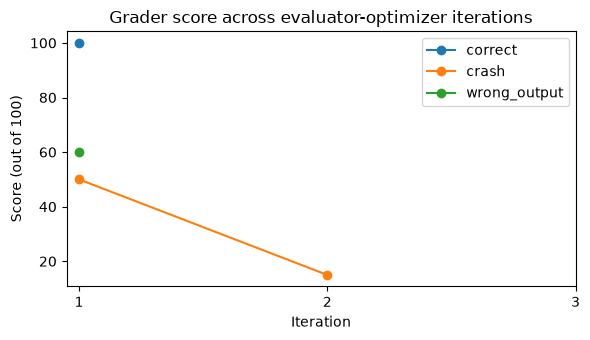

In [7]:
try:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(6, 3.5))
    for name, group in history_df.groupby("case"):
        ax.plot(group["iteration"], group["score"], marker="o", label=name)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Score (out of 100)")
    ax.set_xticks(range(1, MAX_ITERATIONS + 1))
    ax.set_title("Grader score across evaluator-optimizer iterations")
    ax.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib is not installed: run `pip install matplotlib` and restart the kernel.")